# theLook Analytics · 04 · Valore del cliente per canale e test geografico

Il notebook 01 e il notebook 03 mostrano che un modello di attribution non può dire a quale canale va il merito di un acquisto: i percorsi tra canali non hanno struttura. Questo notebook risponde alle due domande che servono comunque a chi decide il budget:

1. **Quanto vale un cliente, secondo il canale da cui si è iscritto?** Ricavi e margine nei primi 12 mesi, riacquisto, valore del primo ordine, resi. Da qui, quanto si può spendere al massimo per acquisire un cliente da ogni canale.
2. **Come misurare se Paid Search porta vendite in più?** Il disegno di un test geografico: sospendere Paid Search in alcune aree e confrontarle con le altre. Una simulazione sui dati storici dice quante aree e quante settimane servono.

**Dati**: viste `marts` costruite con `sql/01_staging.sql` e `sql/02_marts.sql`, fotografia dell'8 novembre 2026, taglio al 30 settembre 2026.

**Come eseguirlo**: in Google Colab, con lo stesso account Google del progetto BigQuery. Scrivi l'ID del progetto nella cella qui sotto, poi *Runtime → Esegui tutto*.

In [1]:
# ID del progetto Google Cloud, come nel notebook 01
PROJECT_ID = "thelook-analytics-514008"
if PROJECT_ID.startswith("scrivi-qui"):
    raise ValueError("Scrivi l'ID del progetto Google Cloud in PROJECT_ID, poi riesegui il notebook.")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ACCENT, GREY, DARK = "#118DFF", "#C4CEDA", "#4A5568"
Z = stats.norm.ppf(0.975)
Z_POT = stats.norm.ppf(0.80)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})


def num(x, d=0):
    if pd.isna(x):
        return "–"
    return f"{x:,.{d}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def pct(x, d=1):
    return "–" if pd.isna(x) else num(x * 100, d) + "%"


def dollari(x, d=0):
    return "–" if pd.isna(x) else "$" + num(x, d)


def wilson(k, n):
    p = k / n
    den = 1 + Z ** 2 / n
    centro = (p + Z ** 2 / (2 * n)) / den
    mezzo = Z * np.sqrt(p * (1 - p) / n + Z ** 2 / (4 * n ** 2)) / den
    return centro - mezzo, centro + mezzo


def media_ic(valori, ripetizioni=1000, seme=1):
    """Media con intervallo di confidenza al 95% bootstrap: i ricavi per cliente sono molto asimmetrici."""
    valori = np.asarray(valori, float)
    rng = np.random.default_rng(seme)
    medie = rng.choice(valori, size=(ripetizioni, len(valori)), replace=True).mean(axis=1)
    return valori.mean(), np.quantile(medie, 0.025), np.quantile(medie, 0.975)

In [2]:
from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery
client = bigquery.Client(project=PROJECT_ID)


def run(sql):
    return client.query(sql).to_dataframe(create_bqstorage_client=False)

## 1 · Quanto vale un cliente, secondo il canale da cui si è iscritto

Entrano i clienti con il **primo acquisto tra gennaio e settembre 2025**: per tutti ci sono 12 mesi pieni prima del taglio del 30 settembre 2026. Per ognuno, nei 12 mesi dal primo acquisto:

- **ricavi netti** (esclusi articoli cancellati e resi) e **margine lordo** (ricavi meno costo dei prodotti);
- numero di ordini, **riacquisto entro 90 giorni**, valore del **primo ordine** e quota di articoli resi.

I ricavi per cliente sono molto asimmetrici (molti clienti con un solo ordine, pochi con tanti), quindi gli intervalli di confidenza delle medie sono calcolati con il bootstrap. Le differenze tra canali si verificano con il test di Kruskal-Wallis per il margine e con il chi-quadro per il riacquisto.

In [3]:
clienti = run(f"""
WITH primi AS (
  SELECT user_id, signup_channel, first_order_date
  FROM `{PROJECT_ID}.marts.dim_users`
  WHERE first_order_date BETWEEN '2025-01-01' AND '2025-09-30'
),
ordini AS (
  SELECT o.user_id, o.order_id, o.order_date, o.net_revenue, o.user_order_number
  FROM `{PROJECT_ID}.marts.fct_orders` AS o
  JOIN primi AS p USING (user_id)
  WHERE o.status != 'cancelled'
    AND o.order_date BETWEEN p.first_order_date AND DATE_ADD(p.first_order_date, INTERVAL 364 DAY)
),
righe AS (
  SELECT i.user_id,
         SUM(IF(NOT i.is_cancelled AND NOT i.is_returned, i.margin, 0)) AS margine_12m,
         COUNTIF(NOT i.is_cancelled) AS articoli,
         COUNTIF(i.is_returned) AS resi
  FROM `{PROJECT_ID}.marts.fct_order_items` AS i
  JOIN primi AS p USING (user_id)
  WHERE i.order_date BETWEEN p.first_order_date AND DATE_ADD(p.first_order_date, INTERVAL 364 DAY)
  GROUP BY i.user_id
)
SELECT p.user_id,
       p.signup_channel AS canale,
       COUNT(o.order_id) AS ordini_12m,
       COALESCE(SUM(o.net_revenue), 0) AS ricavi_12m,
       MAX(IF(o.user_order_number = 1, o.net_revenue, NULL)) AS primo_ordine,
       COALESCE(LOGICAL_OR(o.user_order_number = 2
                AND DATE_DIFF(o.order_date, p.first_order_date, DAY) <= 90), FALSE) AS riacquisto_90,
       COALESCE(ANY_VALUE(r.margine_12m), 0) AS margine_12m,
       COALESCE(ANY_VALUE(r.articoli), 0) AS articoli,
       COALESCE(ANY_VALUE(r.resi), 0) AS resi
FROM primi AS p
LEFT JOIN ordini AS o USING (user_id)
LEFT JOIN righe AS r USING (user_id)
GROUP BY 1, 2
""")
for col in ["ordini_12m", "ricavi_12m", "primo_ordine", "margine_12m", "articoli", "resi"]:
    clienti[col] = pd.to_numeric(clienti[col], errors="coerce").astype(float)
clienti["riacquisto_90"] = clienti["riacquisto_90"].astype(bool)
print(f"{num(len(clienti))} clienti con il primo acquisto tra gennaio e settembre 2025")
print(clienti["canale"].value_counts().to_string())

10.895 clienti con il primo acquisto tra gennaio e settembre 2025
canale
Paid Search       7627
Organic Search    1627
Social             652
Email              551
Display            438


In [4]:
righe = []
for canale, g in clienti.groupby("canale"):
    ricavi, r_lo, r_hi = media_ic(g["ricavi_12m"])
    margine, m_lo, m_hi = media_ic(g["margine_12m"])
    rq_lo, rq_hi = wilson(g["riacquisto_90"].sum(), len(g))
    righe.append({"canale": canale, "clienti": len(g),
                  "ricavi_12m": ricavi, "ricavi_basso": r_lo, "ricavi_alto": r_hi,
                  "margine_12m": margine, "margine_basso": m_lo, "margine_alto": m_hi,
                  "riacquisto_90": g["riacquisto_90"].mean(), "riacquisto_basso": rq_lo, "riacquisto_alto": rq_hi,
                  "ordini_12m": g["ordini_12m"].mean(),
                  "primo_ordine": g["primo_ordine"].mean(),
                  "resi": g["resi"].sum() / max(g["articoli"].sum(), 1)})
valore = pd.DataFrame(righe).sort_values("margine_12m", ascending=False).reset_index(drop=True)

display(pd.DataFrame({
    "canale": valore["canale"], "clienti": valore["clienti"].map(num),
    "ricavi in 12 mesi": valore["ricavi_12m"].map(lambda x: dollari(x, 2)),
    "IC 95%": [f"{dollari(a, 2)} – {dollari(b, 2)}" for a, b in zip(valore["ricavi_basso"], valore["ricavi_alto"])],
    "margine in 12 mesi": valore["margine_12m"].map(lambda x: dollari(x, 2)),
    "riacquisto entro 90 giorni": valore["riacquisto_90"].map(pct),
    "ordini in 12 mesi": valore["ordini_12m"].map(lambda x: num(x, 2)),
    "primo ordine": valore["primo_ordine"].map(lambda x: dollari(x, 2)),
    "resi": valore["resi"].map(pct),
}))

gruppi = [g["margine_12m"].to_numpy() for _, g in clienti.groupby("canale")]
h, p_margine = stats.kruskal(*gruppi)
tab = pd.crosstab(clienti["canale"], clienti["riacquisto_90"])
chi2, p_riacquisto, _, _ = stats.chi2_contingency(tab)
v = np.sqrt(chi2 / tab.to_numpy().sum())
scarto = valore["margine_12m"].max() / valore["margine_12m"].min() - 1
print(f"\nMargine in 12 mesi: differenze tra canali, Kruskal-Wallis p = {p_margine:.2g}; "
      f"il canale migliore supera il peggiore del {pct(scarto)}")
print(f"Riacquisto entro 90 giorni: chi-quadro p = {p_riacquisto:.2g}, V di Cramér = {v:.3f}")

,canale,clienti,ricavi in 12 mesi,IC 95%,margine in 12 mesi,riacquisto entro 90 giorni,ordini in 12 mesi,primo ordine,resi
0,Email,551,"$104,26","$94,56 – $114,59","$54,19","8,9%","1,30","$80,39","10,8%"
1,Paid Search,7.627,"$101,19","$98,55 – $103,85","$52,51","7,3%","1,31","$77,84","11,8%"
2,Display,438,"$99,59","$88,83 – $111,37","$51,69","5,7%","1,28","$76,21","12,5%"
3,Social,652,"$98,70","$88,90 – $109,43","$51,13","7,4%","1,30","$73,88","11,6%"
4,Organic Search,1.627,"$94,23","$89,21 – $99,31","$48,61","6,2%","1,28","$73,85","12,8%"



Margine in 12 mesi: differenze tra canali, Kruskal-Wallis p = 0.11; il canale migliore supera il peggiore del 11,5%
Riacquisto entro 90 giorni: chi-quadro p = 0.18, V di Cramér = 0.024


### Quanto si può spendere per acquisire un cliente

Senza i costi dei canali non si può calcolare il ritorno di ognuno, ma si può dire **quanto si può spendere al massimo** per acquisire un cliente e andare in pareggio nel primo anno: è il margine lordo medio a 12 mesi. La versione prudente usa il limite basso dell'intervallo di confidenza. Chi conosce il costo per cliente di ogni canale lo confronta con questi numeri: se lo supera, quel canale perde soldi nel primo anno.

,canale,"spesa massima per cliente, a pareggio in 12 mesi",versione prudente
0,Email,"$54,19","$49,10"
1,Paid Search,"$52,51","$51,10"
2,Display,"$51,69","$45,99"
3,Social,"$51,13","$45,89"
4,Organic Search,"$48,61","$45,97"


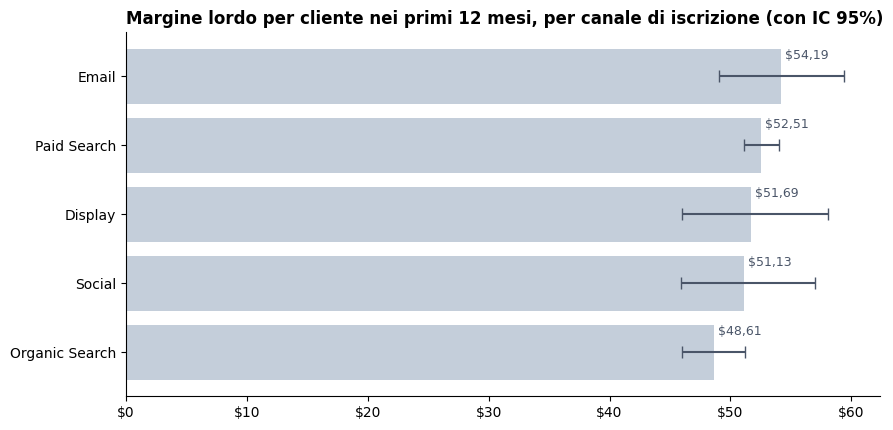

In [5]:
display(pd.DataFrame({
    "canale": valore["canale"],
    "spesa massima per cliente, a pareggio in 12 mesi": valore["margine_12m"].map(lambda x: dollari(x, 2)),
    "versione prudente": valore["margine_basso"].map(lambda x: dollari(x, 2)),
}))

ordine = valore.sort_values("margine_12m")
fig, ax = plt.subplots(figsize=(9, 0.6 * len(ordine) + 1.4))
y = np.arange(len(ordine))
ax.barh(y, ordine["margine_12m"], color=GREY)
ax.errorbar(ordine["margine_12m"], y,
            xerr=[ordine["margine_12m"] - ordine["margine_basso"], ordine["margine_alto"] - ordine["margine_12m"]],
            fmt="none", ecolor=DARK, capsize=4)
for yi, val in zip(y, ordine["margine_12m"]):
    ax.text(val, yi + 0.3, " " + dollari(val, 2), va="center", fontsize=9, color=DARK)
ax.set_yticks(y, ordine["canale"])
ax.xaxis.set_major_formatter(lambda x, _: "$" + num(x))
ax.set_title("Margine lordo per cliente nei primi 12 mesi, per canale di iscrizione (con IC 95%)")
plt.tight_layout()
plt.show()

## 2 · Il disegno del test geografico

L'unico modo per sapere se Paid Search porta vendite **in più**, e non solo vendite che sarebbero arrivate comunque, è spegnerlo in alcune aree e confrontarle con le altre (*geo holdout*).

Prima di farlo bisogna sapere se il test può vedere qualcosa. I ricavi delle aree oscillano da sole, settimana dopo settimana: il test deve distinguere l'effetto della sospensione da queste oscillazioni. Per misurarle si simula il test sui dati storici, **senza spegnere niente** (*test A/A*): si sceglie a caso il 30% delle aree come "test", si confrontano i loro ricavi con quelli delle altre prima e durante il periodo, e si ripete migliaia di volte. Quanto oscilla il risultato quando l'effetto vero è zero dice qual è il più piccolo effetto che il test può vedere.

- **Aree**: le regioni dei clienti (stati e province), escluse le più piccole.
- **Stima dell'effetto**: rapporto tra i ricavi delle aree di test e quelli delle aree di controllo, durante il test diviso prima del test.
- **Effetto massimo atteso**: se Paid Search fosse del tutto incrementale, spegnerlo toglierebbe i ricavi dei primi ordini dei clienti che arrivano da Paid Search. È il tetto dell'effetto che il test può trovare.

In [6]:
settimanale = run(f"""
SELECT CONCAT(u.country, ' · ', COALESCE(u.state, 'n.d.')) AS regione,
       DATE_TRUNC(o.order_date, WEEK(MONDAY)) AS settimana,
       SUM(o.net_revenue) AS ricavi,
       SUM(IF(o.user_order_number = 1 AND u.signup_channel = 'Paid Search', o.net_revenue, 0)) AS ricavi_nuovi_paid
FROM `{PROJECT_ID}.marts.fct_orders` AS o
JOIN `{PROJECT_ID}.marts.dim_users` AS u USING (user_id)
WHERE o.status != 'cancelled'
  AND o.order_date BETWEEN '2025-09-29' AND '2026-09-27'
GROUP BY 1, 2
""")
settimanale["ricavi"] = settimanale["ricavi"].astype(float)
settimanale["ricavi_nuovi_paid"] = settimanale["ricavi_nuovi_paid"].astype(float)
matrice = settimanale.pivot_table(index="regione", columns="settimana", values="ricavi", aggfunc="sum", fill_value=0)
matrice = matrice.loc[:, sorted(matrice.columns)]

totali = matrice.sum(axis=1).sort_values(ascending=False)
copertura = totali.cumsum() / totali.sum()
tenute = totali.index[(copertura <= 0.95) | (np.arange(len(totali)) < 30)]
R = matrice.loc[tenute].to_numpy()
quota_paid = settimanale["ricavi_nuovi_paid"].sum() / settimanale["ricavi"].sum()
ricavi_settimana = settimanale["ricavi"].sum() / matrice.shape[1]

print(f"{matrice.shape[1]} settimane, {num(len(matrice))} regioni; nel test entrano le {num(len(tenute))} "
      f"che fanno il 95% dei ricavi")
print(f"Ricavi medi a settimana: {dollari(ricavi_settimana)}")
print(f"Quota dei ricavi dai primi ordini dei clienti arrivati da Paid Search: {pct(quota_paid)} "
      f"(effetto massimo atteso, se Paid Search fosse del tutto incrementale)")

52 settimane, 227 regioni; nel test entrano le 129 che fanno il 95% dei ricavi
Ricavi medi a settimana: $52.065
Quota dei ricavi dai primi ordini dei clienti arrivati da Paid Search: 41,8% (effetto massimo atteso, se Paid Search fosse del tutto incrementale)


In [7]:
def simula(R, settimane_test, quota_test=0.30, settimane_prima=13, ripetizioni=3000, seme=11):
    """Test A/A: stima dell'effetto quando l'effetto vero è zero, su assegnazioni e periodi a caso."""
    rng = np.random.default_rng(seme)
    n_aree, n_sett = R.shape
    ordine = np.argsort(-R.sum(axis=1))
    stime = np.empty(ripetizioni)
    for i in range(ripetizioni):
        # assegnazione stratificata: in ogni blocco di 10 aree simili per ricavi, il 30% va nel test
        test = np.zeros(n_aree, bool)
        for blocco in np.array_split(ordine, max(1, n_aree // 10)):
            k = max(1, int(round(len(blocco) * quota_test)))
            test[rng.choice(blocco, size=k, replace=False)] = True
        inizio = rng.integers(settimane_prima, n_sett - settimane_test + 1)
        prima = slice(inizio - settimane_prima, inizio)
        durante = slice(inizio, inizio + settimane_test)
        rapporto_prima = R[test, prima].sum() / R[~test, prima].sum()
        rapporto_durante = R[test, durante].sum() / R[~test, durante].sum()
        stime[i] = rapporto_durante / rapporto_prima - 1
    return stime


righe, simulazioni = [], {}
for settimane in [4, 6, 8, 12]:
    stime = simula(R, settimane)
    simulazioni[settimane] = stime
    mde = (Z + Z_POT) * stime.std()
    righe.append({"settimane di test": settimane,
                  "oscillazione senza effetto (95%)": f"{pct(np.quantile(stime, 0.025))} – {pct(np.quantile(stime, 0.975))}",
                  "effetto minimo rilevabile": mde,
                  "vede un'incrementalità di Paid Search dal": mde / quota_paid if quota_paid > 0 else np.nan})
piano_geo = pd.DataFrame(righe)
display(pd.DataFrame({
    "settimane di test": piano_geo["settimane di test"],
    "oscillazione senza effetto (95%)": piano_geo["oscillazione senza effetto (95%)"],
    "effetto minimo rilevabile sui ricavi": piano_geo["effetto minimo rilevabile"].map(pct),
    "incrementalità minima rilevabile di Paid Search": piano_geo["vede un'incrementalità di Paid Search dal"].map(pct),
}))

,settimane di test,oscillazione senza effetto (95%),effetto minimo rilevabile sui ricavi,incrementalità minima rilevabile di Paid Search
0,4,"-14,3% – 17,1%","22,5%","53,9%"
1,6,"-12,6% – 14,6%","19,3%","46,3%"
2,8,"-11,8% – 13,6%","17,8%","42,6%"
3,12,"-10,5% – 11,6%","15,8%","37,8%"


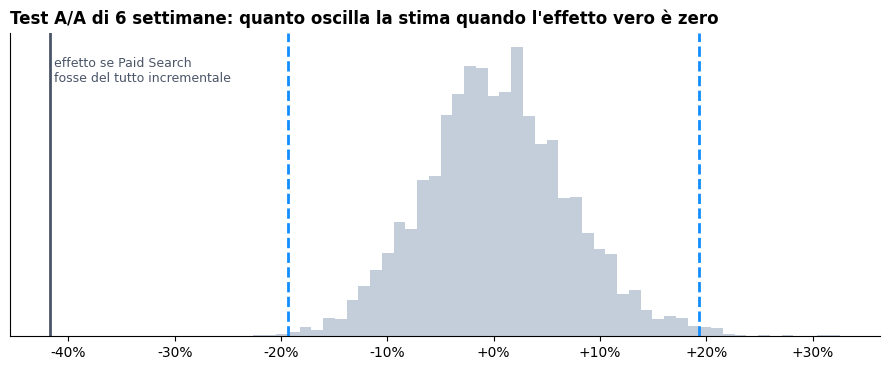

Disegno consigliato: Paid Search sospeso nel 30% delle regioni, scelte a caso dentro blocchi di regioni simili, per 6 settimane, confrontate con le altre e con le 13 settimane precedenti.
Effetto minimo rilevabile sui ricavi delle aree di test: 19,3%; incrementalità minima di Paid Search rilevabile: 46,3%.
Costo massimo del test, se Paid Search fosse del tutto incrementale: $39.136 di ricavi (1,45% dei ricavi di un anno).


In [8]:
# Disegno consigliato: il test più breve che vede un'incrementalità di Paid Search del 50% o meno
adatti = piano_geo[piano_geo["vede un'incrementalità di Paid Search dal"] <= 0.5]
scelta = adatti.iloc[0] if len(adatti) else piano_geo.iloc[-1]
W = int(scelta["settimane di test"])
costo_massimo = 0.30 * quota_paid * ricavi_settimana * W

stime = simulazioni[W]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(stime * 100, bins=50, color=GREY)
for x in [-scelta["effetto minimo rilevabile"] * 100, scelta["effetto minimo rilevabile"] * 100]:
    ax.axvline(x, color=ACCENT, lw=2, ls="--")
ax.axvline(-quota_paid * 100, color=DARK, lw=2)
ax.text(-quota_paid * 100, ax.get_ylim()[1] * 0.92, " effetto se Paid Search\n fosse del tutto incrementale",
        fontsize=9, color=DARK, va="top")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:+.0f}%")
ax.set_yticks([])
ax.set_title(f"Test A/A di {W} settimane: quanto oscilla la stima quando l'effetto vero è zero")
plt.tight_layout()
plt.show()

print(f"Disegno consigliato: Paid Search sospeso nel 30% delle regioni, scelte a caso dentro blocchi di regioni simili, "
      f"per {W} settimane, confrontate con le altre e con le {13} settimane precedenti.")
incrementalita = scelta["vede un'incrementalità di Paid Search dal"]
print(f"Effetto minimo rilevabile sui ricavi delle aree di test: {pct(scelta['effetto minimo rilevabile'])}; "
      f"incrementalità minima di Paid Search rilevabile: {pct(incrementalita)}.")
print(f"Costo massimo del test, se Paid Search fosse del tutto incrementale: {dollari(costo_massimo)} di ricavi "
      f"({pct(costo_massimo / (ricavi_settimana * 52), 2)} dei ricavi di un anno).")

## 3 · Cosa raccogliere da subito

Il test geografico misura un canale alla volta. Per poter usare in futuro anche l'attribution e il marketing mix modeling servono dati che oggi mancano:

- **un canale per ogni sessione**, con i parametri UTM (sorgente, mezzo, campagna) salvati anche per gli utenti già iscritti, non solo all'iscrizione;
- **tutti i contatti di un cliente prima dell'acquisto**, compresi quelli senza clic: impression di campagne, email aperte;
- **i costi per canale e per settimana**, per calcolare il ritorno di ogni canale e confrontarlo con la spesa massima per cliente della sezione 1;
- **un calendario delle iniziative** (promozioni, saldi, campagne), per non attribuire a un canale l'effetto di una promozione.

## 4 · Lettura dei risultati

Esecuzione dell'8 novembre 2026 sulla fotografia dei dati di theLook. È un progetto di studio su dati sintetici: i numeri servono a mostrare il metodo.

**I canali portano clienti di valore simile.** Nei 12 mesi dal primo acquisto, un cliente vale in media tra $48,61 (Organic Search) e $54,19 (Email) di margine lordo. Le differenze non sono statisticamente significative (Kruskal-Wallis p = 0,11), e nemmeno quelle nel riacquisto entro 90 giorni, che va dal 5,7% all'8,9% (chi-quadro p = 0,18). Anche primo ordine, numero di ordini e resi sono vicini.

**Cosa significa per il budget.** Se i clienti valgono uguale, i canali vanno scelti in base al costo per cliente. Per andare in pareggio nel primo anno si può spendere al massimo circa $50 per cliente: $52,51 per Paid Search, $51,10 nella versione prudente. Un canale che costa di più perde soldi nel primo anno.

**Il test geografico è fattibile.** I primi ordini dei clienti che arrivano da Paid Search valgono il 41,8% dei ricavi: è l'effetto massimo, se Paid Search fosse del tutto incrementale. Sospendendolo nel 30% delle regioni per 6 settimane, il test vede un calo dei ricavi dal 19,3% in su, cioè un'incrementalità di Paid Search dal 46% in su. Nel caso peggiore costa $39.136 di ricavi, l'1,45% di un anno. Con 12 settimane vedrebbe un'incrementalità dal 38%, al doppio del costo.

**Raccomandazioni**

1. Fissare un tetto di spesa di circa $50 per cliente acquisito, uguale per tutti i canali, finché i costi reali non mostrano differenze.
2. Lanciare il test geografico su Paid Search: 30% delle regioni, scelte a caso dentro blocchi di regioni simili, per 6 settimane.
3. Iniziare subito a raccogliere i dati della sezione 3, per poter usare in futuro attribution e marketing mix modeling.